In [31]:
%pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


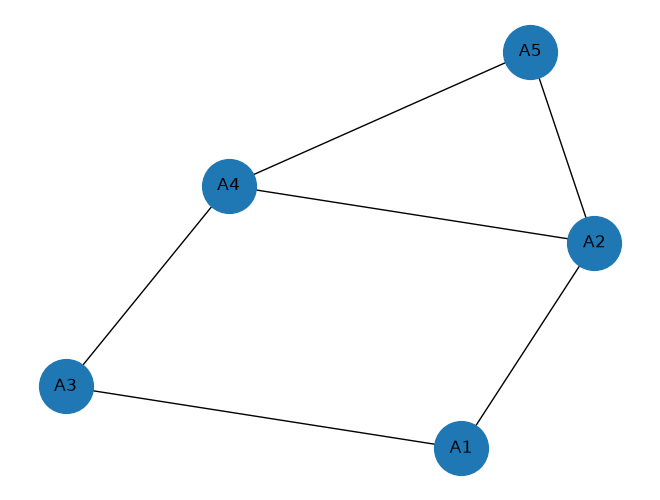

In [32]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_nodes_from(["A1", "A2", "A3", "A4", "A5"])

G.add_edges_from([
    ("A1", "A2"),
    ("A1", "A3"),
    ("A2", "A4"),
    ("A2", "A5"),
    ("A3", "A4"),
    ("A4", "A5")
])

nx.draw(G, with_labels=True, node_size=1500)
plt.show()

In [33]:
cliques = list(nx.find_cliques(G))

print("Maximal cliques:")
for clique in cliques:
    print(clique)

Maximal cliques:
['A2', 'A5', 'A4']
['A2', 'A1']
['A3', 'A1']
['A3', 'A4']


In [34]:
import itertools

# Generate all possible states for 5 nodes (0 or 1)
states = list(itertools.product([0, 1], repeat=5))

for state in states:
    print(state)

(0, 0, 0, 0, 0)
(0, 0, 0, 0, 1)
(0, 0, 0, 1, 0)
(0, 0, 0, 1, 1)
(0, 0, 1, 0, 0)
(0, 0, 1, 0, 1)
(0, 0, 1, 1, 0)
(0, 0, 1, 1, 1)
(0, 1, 0, 0, 0)
(0, 1, 0, 0, 1)
(0, 1, 0, 1, 0)
(0, 1, 0, 1, 1)
(0, 1, 1, 0, 0)
(0, 1, 1, 0, 1)
(0, 1, 1, 1, 0)
(0, 1, 1, 1, 1)
(1, 0, 0, 0, 0)
(1, 0, 0, 0, 1)
(1, 0, 0, 1, 0)
(1, 0, 0, 1, 1)
(1, 0, 1, 0, 0)
(1, 0, 1, 0, 1)
(1, 0, 1, 1, 0)
(1, 0, 1, 1, 1)
(1, 1, 0, 0, 0)
(1, 1, 0, 0, 1)
(1, 1, 0, 1, 0)
(1, 1, 0, 1, 1)
(1, 1, 1, 0, 0)
(1, 1, 1, 0, 1)
(1, 1, 1, 1, 0)
(1, 1, 1, 1, 1)


In [35]:
import numpy as np

beta = 1
weights = []

# Calculate the weight for each state
for state in states:

    # Associate each node with its value (0 or 1)
    values = dict(zip(["A1", "A2", "A3", "A4", "A5"], state))

    energy = 0

    # Go through each maximal clique
    for clique in cliques:

        # Get all pairs of nodes in the clique
        pairs = list(itertools.combinations(clique, 2))

        for pair in pairs:
            a = pair[0]
            b = pair[1]

            value_a = values[a]
            value_b = values[b]

            product = value_a * value_b
            energy += product

    # Calculate the weight of the current state
    weight = np.exp(beta * energy)
    weights.append(weight)

# Calculate normalization constant
Z = sum(weights)

print("Normalization constant Z:", Z)


Normalization constant Z: 706.2787274114462


In [36]:
# Calculate probabilities
probabilities = []

for weight in weights:
    probabilities.append(weight / Z)

# Print all configurations and probabilities
for state, probability in zip(states, probabilities):
    print(state, "->", round(probability, 6))


# Find the most probable configurations
max_probability = max(probabilities)

print("\nMost probable configurations:")

for state, probability in zip(states, probabilities):
    if np.isclose(probability, max_probability):
        print(state, "->", probability)

(0, 0, 0, 0, 0) -> 0.001416
(0, 0, 0, 0, 1) -> 0.001416
(0, 0, 0, 1, 0) -> 0.001416
(0, 0, 0, 1, 1) -> 0.003849
(0, 0, 1, 0, 0) -> 0.001416
(0, 0, 1, 0, 1) -> 0.001416
(0, 0, 1, 1, 0) -> 0.003849
(0, 0, 1, 1, 1) -> 0.010462
(0, 1, 0, 0, 0) -> 0.001416
(0, 1, 0, 0, 1) -> 0.003849
(0, 1, 0, 1, 0) -> 0.003849
(0, 1, 0, 1, 1) -> 0.028439
(0, 1, 1, 0, 0) -> 0.001416
(0, 1, 1, 0, 1) -> 0.003849
(0, 1, 1, 1, 0) -> 0.010462
(0, 1, 1, 1, 1) -> 0.077304
(1, 0, 0, 0, 0) -> 0.001416
(1, 0, 0, 0, 1) -> 0.001416
(1, 0, 0, 1, 0) -> 0.001416
(1, 0, 0, 1, 1) -> 0.003849
(1, 0, 1, 0, 0) -> 0.003849
(1, 0, 1, 0, 1) -> 0.003849
(1, 0, 1, 1, 0) -> 0.010462
(1, 0, 1, 1, 1) -> 0.028439
(1, 1, 0, 0, 0) -> 0.003849
(1, 1, 0, 0, 1) -> 0.010462
(1, 1, 0, 1, 0) -> 0.010462
(1, 1, 0, 1, 1) -> 0.077304
(1, 1, 1, 0, 0) -> 0.010462
(1, 1, 1, 0, 1) -> 0.028439
(1, 1, 1, 1, 0) -> 0.077304
(1, 1, 1, 1, 1) -> 0.571203

Most probable configurations:
(1, 1, 1, 1, 1) -> 0.5712033759976402


**Conclusion (b)**

The most probable configuration is (1, 1, 1, 1, 1), with a probability of approximately 0.5712.

This happens because the model favors configurations where connected nodes are both equal to 1.

## c) Modification of the potentials

To favor neighboring nodes having the same value,
we can define the following potential:

$$
\phi_{ij}(a_i,a_j) = e^{\beta \mathbf{1}(a_i=a_j)}
$$

where $\beta > 0$.

This gives a higher weight to configurations where
connected nodes have the same value (both 0 or both 1).

**Conclusion (c)**

To obtain the Ising model, we modify the potential functions so that neighboring variables with the same value receive a higher weight.

For positive beta, the pairs (0,0) and (1,1) are favored over (0,1) and (1,0).

This encourages neighboring variables to have the same state.